## 1. Loading library & raw dataset

In [215]:
#Load Libraries
import pandas as pd

In [216]:
#Load Raw Data
df_raw = pd.read_csv('../data/raw/automobileEDA_dirty_training.csv')
df_raw.sample(5)

,transaction_date,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
145,26/05/2025,0,85,subaru,turbo,four,wagon,4wd,front,96.9,...,7.7,111.0,4800.0,23,23,11694.0,10.217391,Medium,0,1
183,03-Jul-2025,2,94,volkswagen,turbo,four,sedan,fwd,front,97.3,...,23.0,68.0,4500.0,37,42,9495.0,6.351351,Low,1,0
167,17-Jun-2025,2,134,toyota,std,two,hatchback,rwd,front,98.4,...,9.3,116.0,4800.0,24,30,11549.0,9.791667,Medium,0,1
27,28-Jan-2025,-1,110,dodge,std,four,wagon,fwd,front,103.3,...,8.5,88.0,5000.0,24,30,8921.0,9.791667,Low,0,1
164,2025-06-14,2,134,toyota,std,two,hardtop,rwd,front,98.4,...,9.3,116.0,4800.0,24,30,9639.0,9.791667,Medium,0,1


## 2. Identifikasi dan cleaning data : Categorical

### 2.a. Cek missing value

In [217]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_date   203 non-null    str    
 1   symboling          205 non-null    int64  
 2   normalized-losses  205 non-null    int64  
 3   make               203 non-null    str    
 4   aspiration         205 non-null    str    
 5   num-of-doors       203 non-null    str    
 6   body-style         205 non-null    str    
 7   drive-wheels       205 non-null    str    
 8   engine-location    205 non-null    str    
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    str    
 15  num-of-cylinders   205 non-null    str    
 16  engine-size        205 non-null    in

In [218]:
#Check kolom yang memiliki missing values
df_raw.isna().sum()

transaction_date     2
symboling            0
normalized-losses    0
make                 2
aspiration           0
num-of-doors         2
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           3
peak-rpm             0
city-mpg             0
highway-mpg          0
price                3
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [219]:
df_raw.columns[df_raw.isna().any()]

Index(['transaction_date', 'make', 'num-of-doors', 'stroke', 'horsepower',
       'price', 'horsepower-binned'],
      dtype='str')

In [220]:
df_raw[df_raw.columns[df_raw.isna().any()]].sample(5)

,transaction_date,make,num-of-doors,stroke,horsepower,price,horsepower-binned
163,13-Jun-2025,toyota,two,3.50,116.0,8449.0,Medium
133,14/05/2025,saab,four,3.07,160.0,18620.0,High
145,26/05/2025,subaru,four,2.64,111.0,11694.0,Medium
37,07/02/2025,honda,two,3.58,86.0,9095.0,Low
171,21-Jun-2025,toyota,four,3.54,92.0,9988.0,Low


In [221]:
df_raw[df_raw.columns[df_raw.isna().any()]].isna().sum()

transaction_date     2
make                 2
num-of-doors         2
stroke               4
horsepower           3
price                3
horsepower-binned    1
dtype: int64

#### Kesimpulan: 
1. kolom yang memiliki missing values adalah 'transaction_date', 'make', 'num-of-doors', 'stroke', 'horsepower', 'price', 'horsepower-binned'
2. Jumlah missing value sedikit dapat dilakukan `drop rows`

In [222]:
df_processed = df_raw.dropna()
df_processed

,transaction_date,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,2025-01-01,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,02/01/2025,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,01-03-2025,1,122,ALFA-ROMERO,std,two,hatchback,rwd,front,94.5,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,04-Jan-2025,2,164,audi,std,four,sedan,fwd,front,99.8,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2025-01-05,2,164,audi,std,four,sedan,4wd,front,99.4,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199,19-Jul-2025,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,...,23.0,106.0,4800.0,26,27,22470.0,9.038462,Medium,1,0
200,2025-07-20,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,...,9.5,114.0,5400.0,19,25,22625.0,12.368421,Medium,0,1
201,06/01/2025,2,122,audi,std,two,sedan,fwd,front,99.8,...,8.5,110.0,5500.0,19,25,15250.0,12.368421,Medium,0,1
202,26/01/2025,1,148,dodge,std,four,sedan,fwd,front,93.7,...,9.4,68.0,5500.0,31,38,7609.0,7.580645,Low,0,1


###  2.b Cek duplicate values

In [223]:
df_processed.duplicated().sum()

np.int64(3)

In [224]:
df_processed = df_processed.drop_duplicates(keep='first')
df_processed

,transaction_date,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,2025-01-01,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,02/01/2025,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,01-03-2025,1,122,ALFA-ROMERO,std,two,hatchback,rwd,front,94.5,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,04-Jan-2025,2,164,audi,std,four,sedan,fwd,front,99.8,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2025-01-05,2,164,audi,std,four,sedan,4wd,front,99.4,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,2025-07-16,-1,95,volvo,std,four,sedan,rwd,front,109.1,...,9.5,114.0,5400.0,23,28,16845.0,10.217391,Medium,0,1
197,17/07/2025,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,...,8.7,160.0,5300.0,19,25,19045.0,12.368421,High,0,1
198,07-18-2025,-1,95,volvo,std,four,sedan,rwd,front,109.1,...,8.8,134.0,5500.0,18,23,21485.0,13.055556,Medium,0,1
199,19-Jul-2025,-1,95,volvo,turbo,four,sedan,rwd,front,109.1,...,23.0,106.0,4800.0,26,27,22470.0,9.038462,Medium,1,0


#### Kesimpulan: terdapat 3 baris duplikat, drop 2 duplikat simpan 1 baris orginal

### 2.c. Cek tipe data

In [225]:
df_processed.sample(5)

,transaction_date,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
43,13-Feb-2025,2,122,isuzu,std,two,hatchback,rwd,front,96.0,...,9.2,90.0,5000.0,24,29,11048.0,9.791667,Low,0,1
165,15/06/2025,2,134,toyota,std,two,hatchback,rwd,front,98.4,...,9.3,116.0,4800.0,24,30,9989.0,9.791667,Medium,0,1
108,2025-04-19,0,161,peugot,std,four,sedan,rwd,front,107.9,...,8.4,95.0,5000.0,19,24,15580.0,12.368421,Low,0,1
122,05-03-2025,3,186,porsche,std,two,hatchback,rwd,front,94.5,...,9.5,143.0,5500.0,19,27,22018.0,12.368421,Medium,0,1
96,2025-04-07,0,106,nissan,std,four,hatchback,fwd,front,97.2,...,8.5,97.0,5200.0,27,34,8949.0,8.703704,Low,0,1


In [226]:
df_processed.dtypes

transaction_date         str
symboling              int64
normalized-losses      int64
make                     str
aspiration               str
num-of-doors             str
body-style               str
drive-wheels             str
engine-location          str
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type              str
num-of-cylinders         str
engine-size            int64
fuel-system              str
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
city-L/100km         float64
horsepower-binned        str
diesel                 int64
gas                    int64
dtype: object

#### Kesimpulan :
1. transaction_date seharusnya bertipe `date time`
2. num-of-doors seharusnya bertipe `integer`
3. num-of-cylinders seharusnya bertipe `integer`

### 2.d. Cek konsistensi/format data

In [227]:
#cek categorical columns
df_processed.select_dtypes(include='object').columns

C:\Users\Ilham\AppData\Local\Temp\ipykernel_21792\142256829.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_processed.select_dtypes(include='object').columns


Index(['transaction_date', 'make', 'aspiration', 'num-of-doors', 'body-style',
       'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders',
       'fuel-system', 'horsepower-binned'],
      dtype='str')

#### Cek dan cleaning : `transaction_date`

In [228]:
#cek nilai pada `transaction_date` column
df_processed['transaction_date'].head()

0     2025-01-01
1     02/01/2025
2     01-03-2025
3    04-Jan-2025
4     2025-01-05
Name: transaction_date, dtype: str

In [229]:
#Parsing `transaction_date` column to datetime format dengan beberapa tipe format tanggal yang berbeda.
formats = ['%Y-%m-%d', '%d/%m/%Y', '%m-%d-%Y', '%d-%b-%Y']

date_strip = df_processed['transaction_date'].str.strip()
parsed = pd.Series(pd.NaT, index=date_strip.index)

for fmt in formats:
    parsed = parsed.fillna(pd.to_datetime(date_strip, format=fmt, errors='coerce'))

df_processed['transaction_date'] = parsed.dt.strftime('%d-%m-%Y')
df_processed['transaction_date'].sample(5)

47     17-02-2025
173    23-06-2025
98     09-04-2025
195    15-07-2025
127    08-05-2025
Name: transaction_date, dtype: str

In [230]:
df_processed['transaction_date'].isna().sum()

np.int64(0)

#### Cek dan cleaning : `aspiration`, `num-of-doors`, `body-style`, `drive-wheels`, `engine-location`, `engine-type`, `num-of-cylinders`, `fuel-system`, `horsepower-binned`

In [231]:
#cek nilai pada `make` column
df_processed['make'].unique()

<ArrowStringArray>
[  'alfa-romero',   'ALFA-ROMERO',          'audi',           'bmw',
     'chevrolet',         'dodge',       'dodge  ',         'honda',
          'Audi',         'isuzu',        'jaguar',         'mazda',
 'mercedes-benz',     'mercury  ',    'mitsubishi',           'BMW',
        'nissan',        'peugot',        'toyota',      'plymouth',
       'porsche',     'porsche  ',       'renault',          'saab',
        'subaru',    'volkswagen',         'volvo']
Length: 27, dtype: str

In [232]:
#Cleaning `make` column menghapus spasi di awal dan akhir string, serta mengubah semua huruf menjadi huruf kecil.
df_processed['make'] = df_processed['make'].str.strip().str.lower()

In [233]:
#cek nilai pada 'aspiration' column
df_processed['aspiration'].unique()

<ArrowStringArray>
['std', 'turbo']
Length: 2, dtype: str

In [234]:
#cek nilai pada 'num-of-doors' column
df_processed['num-of-doors'].unique()

<ArrowStringArray>
['two', 'four']
Length: 2, dtype: str

In [235]:
#cek nilai pada `body-style` column
df_processed['body-style'].unique()

<ArrowStringArray>
['convertible', 'hatchback', 'sedan', 'wagon', 'SEDAN', 'Sedan', 'hardtop']
Length: 7, dtype: str

In [236]:
#standardisasi nilai pada `body-style` column dengan menghapus spasi di awal dan akhir string, serta mengubah semua huruf menjadi huruf kecil.
df_processed['body-style'] = df_processed['body-style'].str.strip().str.lower()

In [259]:
#cek nilai pada `drive-wheels` column
df_processed['drive-wheels'].unique()

<ArrowStringArray>
['rwd', 'fwd', '4wd']
Length: 3, dtype: str

In [258]:
#standarisasi nilai pada `drive-wheels`
df_processed['drive-wheels'] = df_processed['drive-wheels'].str.strip().str.lower().replace('awd', '4wd')

In [238]:
#standarisasi nilai pada `drive-wheels` column dengan menghapus spasi di awal dan akhir string, serta mengubah semua huruf menjadi huruf kecil.
df_processed['drive-wheels'] = df_processed['drive-wheels'].str.strip().str.lower()

In [239]:
#cek nilai pada `engine-location` column
df_processed['engine-location'].unique()

<ArrowStringArray>
['front', 'rear']
Length: 2, dtype: str

In [240]:
#cek nilai pada `engine-type` column
df_processed['engine-type'].unique()

<ArrowStringArray>
['dohc', 'ohcv', 'ohc', 'l', 'ohcf']
Length: 5, dtype: str

In [241]:
#cek nilai pada `num-of-cylinders` column
df_processed['num-of-cylinders'].unique()

<ArrowStringArray>
['four', 'six', 'five', 'three', 'eight']
Length: 5, dtype: str

In [242]:
#cek nilai pada `fuel-system` column
df_processed['fuel-system'].unique()

<ArrowStringArray>
['mpfi', '2bbl', 'MPFI', 'mfi', '1bbl', 'spfi', 'idi', 'Mpfi', 'spdi']
Length: 9, dtype: str

In [243]:
#standarisasi nilai pada `fuel-system` column dengan menghapus spasi di awal dan akhir string, serta mengubah semua huruf menjadi huruf kecil.
df_processed['fuel-system'] = df_processed['fuel-system'].str.strip().str.lower()

In [244]:
#cek nilai pada `horsepower-binned` column
df_processed['horsepower-binned'].unique()

<ArrowStringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str

## 3. Identifikasi dan cleaning data : Numerical

In [245]:
#cek numerical columns
numerical = df_processed.select_dtypes(include='number').columns
numerical

Index(['symboling', 'normalized-losses', 'wheel-base', 'length', 'width',
       'height', 'curb-weight', 'engine-size', 'bore', 'stroke',
       'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg',
       'highway-mpg', 'price', 'city-L/100km', 'diesel', 'gas'],
      dtype='str')

In [246]:
df_processed[numerical].describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000,186.000000
mean,0.827957,121.919355,98.742473,0.836390,0.914740,53.836559,2543.833333,125.817204,3.326129,3.257312,10.258118,101.642539,5089.520102,25.543011,31.102151,12876.446237,9.755651,0.107527,0.892473
std,1.235718,32.088879,6.023824,0.058817,0.029071,2.328288,508.161731,36.505593,0.270131,0.316918,4.141167,35.490190,464.937422,6.297213,6.700165,7488.291849,2.377679,0.310618,0.310618
min,-2.000000,65.000000,86.600000,0.678039,0.837500,48.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,14.000000,16.000000,5118.000000,4.795918,0.000000,0.000000
25%,0.000000,98.750000,94.500000,0.799135,0.889236,52.000000,2145.000000,98.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,20.250000,25.000000,7747.250000,7.833333,0.000000,1.000000
50%,1.000000,122.000000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5100.000000,25.000000,31.000000,9992.000000,9.400000,0.000000,1.000000
75%,2.000000,137.000000,102.400000,0.881307,0.928125,55.575000,2922.500000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,36.000000,16500.000000,11.610119,0.000000,1.000000
max,3.000000,256.000000,115.600000,0.973570,1.000000,59.800000,4066.000000,304.000000,3.940000,4.170000,23.000000,207.000000,6600.000000,49.000000,54.000000,45400.000000,16.785714,1.000000,1.000000


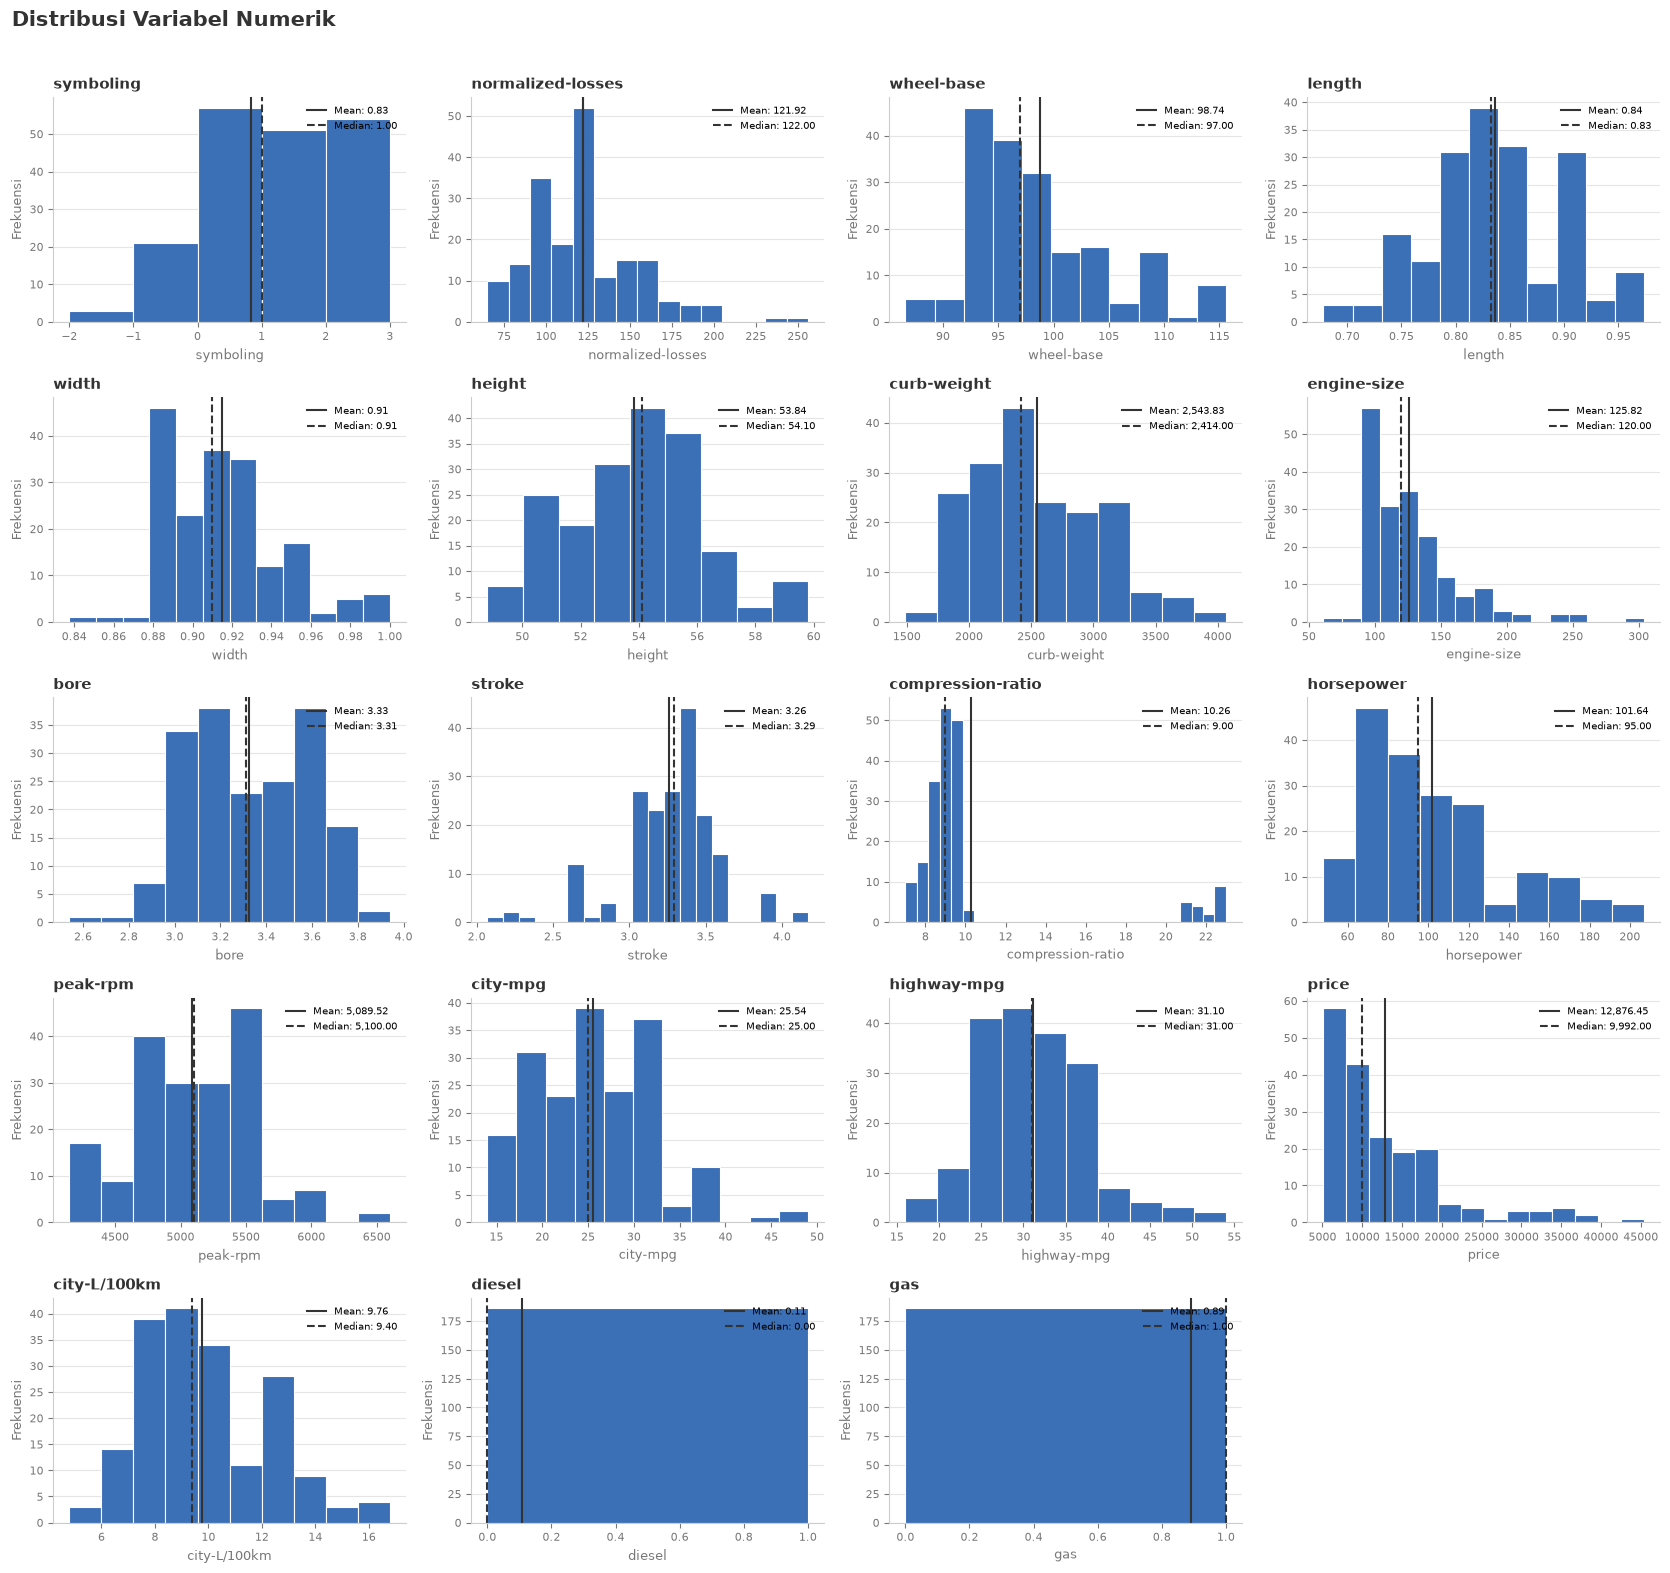

In [247]:
import matplotlib.pyplot as plt
import numpy as np

# Kolom numerik (lewati jika `numerical` sudah didefinisikan sebelumnya)
numerical = df_processed.select_dtypes(include='number').columns.tolist()

n_cols = 4
n_rows = int(np.ceil(len(numerical) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.2 * n_rows))
axes = axes.flatten()

BAR_COLOR = '#3B6FB6'   # satu warna untuk semua histogram (single series)
INK = '#333333'
MUTED = '#777777'

for ax, col in zip(axes, numerical):
    data = df_processed[col].dropna()
    ax.hist(data, bins='auto', color=BAR_COLOR, edgecolor='white', linewidth=0.8)

    # Garis referensi: mean (solid) & median (putus-putus)
    ax.axvline(data.mean(), color=INK, linewidth=1.5, label=f'Mean: {data.mean():,.2f}')
    ax.axvline(data.median(), color=INK, linewidth=1.5, linestyle='--', label=f'Median: {data.median():,.2f}')

    ax.set_title(col, fontsize=11, fontweight='bold', color=INK, loc='left')
    ax.set_xlabel(col, fontsize=9, color=MUTED)
    ax.set_ylabel('Frekuensi', fontsize=9, color=MUTED)
    ax.tick_params(labelsize=8, colors=MUTED)
    ax.grid(axis='y', color='#E5E5E5', linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#CCCCCC')
    ax.legend(fontsize=7, frameon=False, loc='upper right')

# Sembunyikan panel kosong yang tersisa
for ax in axes[len(numerical):]:
    ax.set_visible(False)

fig.suptitle('Distribusi Variabel Numerik', fontsize=15, fontweight='bold', color=INK, x=0.01, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


#### Kesimpulan : secara sebaran data histogram, data numerikal terlihat wajar sehingga tidak perlu dilakukan cleaning lebih lanjut.

## 4. Transformasi Data

### Min-max scalling pada kolom `curb-weight`, `peak-rpm`, dan `price`

In [248]:
#lakukan min-max scaling pada kolom `curb-weight`, `peak-rpm`, dan `price`
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_processed['curb-weight'] = scaler.fit_transform(df_processed[['curb-weight']])
df_processed['peak-rpm'] = scaler.fit_transform(df_processed[['peak-rpm']])
df_processed['price'] = scaler.fit_transform(df_processed[['price']])

In [249]:
df_processed[['curb-weight', 'peak-rpm', 'price']].head()

,curb-weight,peak-rpm,price
0,0.411171,0.346939,0.207959
1,0.411171,0.346939,0.282558
2,0.517843,0.346939,0.282558
3,0.329325,0.551020,0.219254
4,0.518231,0.551020,0.306142


In [250]:
#perbandingan before (raw) vs after (MinMaxScaler) pada kolom numerik yang di-scaling
scaled_cols = ['curb-weight', 'peak-rpm', 'price']

#ambil baris raw yang sama dengan df_processed (karena sudah ada dropna & drop_duplicates)
before = df_raw.loc[df_processed.index, scaled_cols]
after = df_processed[scaled_cols]

#perbandingan nilai per baris
compare_scaled = pd.concat([before, after], axis=1, keys=['before', 'after'])
compare_scaled.head()

before                         after                    
  curb-weight peak-rpm    price curb-weight  peak-rpm     price
0        2548   5000.0  13495.0    0.411171  0.346939  0.207959
1        2548   5000.0  16500.0    0.411171  0.346939  0.282558
2        2823   5000.0  16500.0    0.517843  0.346939  0.282558
3        2337   5500.0  13950.0    0.329325  0.551020  0.219254
4        2824   5500.0  17450.0    0.518231  0.551020  0.306142

### Konversi data angka string menjadi numerik

In [251]:
#konversi 'num-of-doors' column menjadi numerik
df_processed['num-of-doors'] = df_processed['num-of-doors'].replace({'four': 4, 'two': 2}).astype(int)

In [252]:
#perbandingan before (raw) vs after (processed) pada 'num-of-doors' column
compare_doors = pd.DataFrame({
    'before': df_raw.loc[df_processed.index, 'num-of-doors'],
    'after': df_processed['num-of-doors']
})

compare_doors.head()

,before,after
0,two,2
1,two,2
2,two,2
3,four,4
4,four,4


In [253]:
#konversi 'num-of-cylinders' column menjadi numerik
df_processed['num-of-cylinders'] = df_processed['num-of-cylinders'].replace({'four': 4, 'six': 6, 'five': 5, 'three': 3, 'eight': 8}).astype(int)

In [254]:
#perbandingan before (raw) vs after (processed) pada 'num-of-cylinders' column
compare_cylinders = pd.DataFrame({
    'before': df_raw.loc[df_processed.index, 'num-of-cylinders'],
    'after': df_processed['num-of-cylinders']
})

compare_cylinders.head()


,before,after
0,four,4
1,four,4
2,six,6
3,four,4
4,five,5


### Encoding data categorical kolom `horsepower-binned`

In [255]:
#Encoding kolom `horsepower-binned` menjadi one-hot encoding menggunakan `pd.get_dummies()`
dummies = pd.get_dummies(df_processed['horsepower-binned'], prefix='horsepower')
dummies.head()

,horsepower_High,horsepower_Low,horsepower_Medium
0,False,False,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True


In [256]:
df_processed = pd.concat([df_processed, dummies], axis=1)
df_processed.head()

,transaction_date,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas,horsepower_High,horsepower_Low,horsepower_Medium
0,01-01-2025,3,122,alfa-romero,std,2,convertible,rwd,front,88.6,...,21,27,0.207959,11.190476,Medium,0,1,False,False,True
1,02-01-2025,3,122,alfa-romero,std,2,convertible,rwd,front,88.6,...,21,27,0.282558,11.190476,Medium,0,1,False,False,True
2,03-01-2025,1,122,alfa-romero,std,2,hatchback,rwd,front,94.5,...,19,26,0.282558,12.368421,Medium,0,1,False,False,True
3,04-01-2025,2,164,audi,std,4,sedan,fwd,front,99.8,...,24,30,0.219254,9.791667,Medium,0,1,False,False,True
4,05-01-2025,2,164,audi,std,4,sedan,4wd,front,99.4,...,18,22,0.306142,13.055556,Medium,0,1,False,False,True


## Simpan hasil data pipeline ke file CSV baru

In [257]:
## Simpan hasil data pipeline ke file CSV baru
df_processed.to_csv('../data/processed/automobileEDA_processed.csv', index=False)